In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, measure, morphology, io
import scipy.ndimage as ndi
from skimage.color import rgb2gray
from skimage.filters import threshold_multiotsu
from skimage.morphology import skeletonize

print("ready")

ready


In [3]:
manual_thickness_px = [16.964, 8.911, 17.341, 7.674, 5.888, 9.390, 15.710, 10.382, 29.790, 15.715]

MICRONS_PER_PIXEL = 32
manual_thickness_um = [v * MICRONS_PER_PIXEL for v in manual_thickness_px]

print("Manual mean (µm):", np.mean(manual_thickness_um))
print("Manual median (µm):", np.median(manual_thickness_um))
print("Manual std (µm):", np.std(manual_thickness_um))
print()
for i, (px, um) in enumerate(zip(manual_thickness_px, manual_thickness_um), start=1):
    print(f"{i}: {px:.2f} px -> {um:.1f} µm")

Manual mean (µm): 440.84799999999996
Manual median (µm): 417.472
Manual std (µm): 212.4328247630295

1: 16.96 px -> 542.8 µm
2: 8.91 px -> 285.2 µm
3: 17.34 px -> 554.9 µm
4: 7.67 px -> 245.6 µm
5: 5.89 px -> 188.4 µm
6: 9.39 px -> 300.5 µm
7: 15.71 px -> 502.7 µm
8: 10.38 px -> 332.2 µm
9: 29.79 px -> 953.3 µm
10: 15.71 px -> 502.9 µm


1: manual=  542.8  auto=  288.0  diff= +254.8
2: manual=  285.2  auto=  320.0  diff=  -34.8
3: manual=  554.9  auto=  512.0  diff=  +42.9
4: manual=  245.6  auto=  256.0  diff=  -10.4
5: manual=  188.4  auto=  128.0  diff=  +60.4
6: manual=  300.5  auto=  352.0  diff=  -51.5
7: manual=  502.7  auto=  416.0  diff=  +86.7
8: manual=  332.2  auto=  288.0  diff=  +44.2
9: manual=  953.3  auto=  896.0  diff=  +57.3
10: manual=  502.9  auto=  416.0  diff=  +86.9

Mean absolute error: 73.0 µm
Bias (manual − auto): 53.6 µm
95% limits of agreement: -114.1 to 221.4 µm
Correlation (r): 0.924


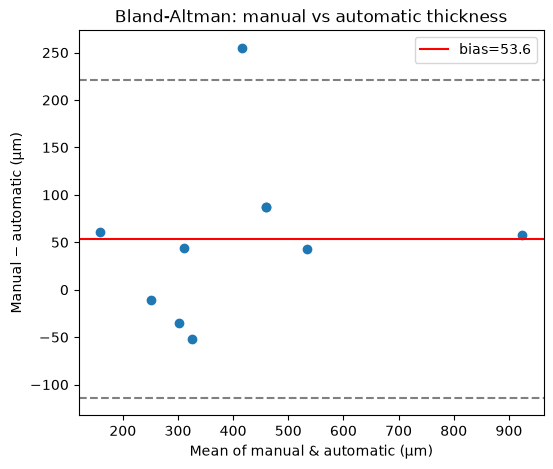

In [4]:
# Automatic measurement at the exact same 10 locations used for manual measurement
auto_thickness_um = [288.0, 320.0, 512.0, 256.0, 128.0, 352.0, 416.0, 288.0, 896.0, 416.0]

diff = np.array(manual_thickness_um) - np.array(auto_thickness_um)
mae = np.mean(np.abs(diff))
bias = np.mean(diff)
sd_diff = np.std(diff, ddof=1)
loa_low, loa_high = bias - 1.96*sd_diff, bias + 1.96*sd_diff
r = np.corrcoef(manual_thickness_um, auto_thickness_um)[0,1]

for i, (m, a, d) in enumerate(zip(manual_thickness_um, auto_thickness_um, diff), start=1):
    print(f"{i}: manual={m:7.1f}  auto={a:7.1f}  diff={d:+7.1f}")

print()
print(f"Mean absolute error: {mae:.1f} µm")
print(f"Bias (manual − auto): {bias:.1f} µm")
print(f"95% limits of agreement: {loa_low:.1f} to {loa_high:.1f} µm")
print(f"Correlation (r): {r:.3f}")

plt.figure(figsize=(6,5))
mean_vals = (np.array(manual_thickness_um)+np.array(auto_thickness_um))/2
plt.scatter(mean_vals, diff)
plt.axhline(bias, color='red', label=f'bias={bias:.1f}')
plt.axhline(loa_low, color='gray', linestyle='--')
plt.axhline(loa_high, color='gray', linestyle='--')
plt.xlabel("Mean of manual & automatic (µm)")
plt.ylabel("Manual − automatic (µm)")
plt.title("Bland-Altman: manual vs automatic thickness")
plt.legend()
plt.show()